# **1. ASR(Automatic Speech Recognition)**
- 자동 음성인식. 사람이 말하는 소리를 컴퓨터가 글자로 바꾸는 기술
- Qwen3-ASR: ASR을 수행하는 AI 모델
- Whisper: OpenAI가 개발한 ASR 모델
- STT: Speech-to-Text의 약자로, 음성을 문자로 변환하는 기능

In [1]:
# 소리 측정: 소리 신호가 얼마나 위쪽 또는 아래쪽으로 흔들리는지 숫자로 표현
import numpy as np

# 마이너는 나쁜 소리가 아니라 파형의 반대 방향을 나타냄
data = np.array([0.0, 0.4, 0.8, 0.4, 0.0, -0.4, -0.8, -0.4], dtype=np.float32)
print("소리의 측정갑: ", data)
print("소리의 측정횟수: ", len(data))
print("가장 큰 절댓값: ", np.max(np.abs(data)))

소리의 측정갑:  [ 0.   0.4  0.8  0.4  0.  -0.4 -0.8 -0.4]
소리의 측정횟수:  8
가장 큰 절댓값:  0.8


### Hz(헤르츠)
- 1초에 몇 번 반복되는가를 나타내는 단위
- 샘플링 레이트(sample rate)를 말할 때 1초에 신호를 몇 번 측정하는가를 뜻함
    - 1 KHz = 1000Hz
    - 16 KHz = 16000Hz
    
> 소리의 주파수(음높이 관련) Hz와 샘플링 레이트 Hz는 서로 다른 개념. 주파수는 소리가 1초에 얼마나 진동하는지, 샘플링 레이트는 컴퓨터가 1초에 몇 번 측정하는지를 말함

In [2]:
sample_rate = 16000
seconds = 4
num_samples = sample_rate * seconds
print(f"{seconds}초 동안 만들어지느 측정값: {num_samples:,}개")

4초 동안 만들어지느 측정값: 64,000개


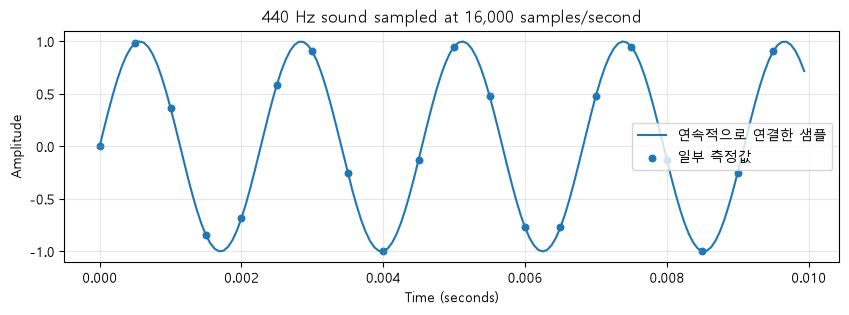

In [3]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

sample_rate = 16000
duration = 0.01
t = np.arange(int(sample_rate * duration)) / sample_rate
frequency = 440
wave = np.sin(2 * np.pi * frequency * t)
plt.figure(figsize=(10, 3))
plt.plot(t, wave, label='연속적으로 연결한 샘플')
plt.scatter(t[::8], wave[::8], s=22, label='일부 측정값')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.title('440 Hz sound sampled at 16,000 samples/second')
plt.legend()
plt.grid(alpha=.3)
plt.show()

### WAV
- 디지털 소리를 담는 파일 형식. 압축되지 않은 PCM 데이터를 저장할 수 있음
- 모노(Moco): 소리 채널이 하나. channels=1
- 스테레오(Stereo): 소리 채널이 2개. channels=2
- float32로 소리 측정값을 저장. 32빝트 부동소수점 수를 뜻함

> 16kHz 모노 4초: (64000,) 모양의 1차원 배열. 녹음 라이브러리는 (64000, 1)처럼 채널 축을 포함해 사용

In [4]:
# soundfile: 음성 파일을 읽거나 저장할 때 사용하는 모듈 <- 파이썬에서만 사용
# 예) wav같은 소리 파일을 숫자 데이터로 가져오거나, 숫자 데이터를 다시 소리 파일로 저장하는 도구
import soundfile as sf  # pip install soundfile

sr = 16000  # 1초에 소리를 16000번 측정
t = np.arange(sr) / sr

# 0.2: 진폭. 만들어지는 소리 신호의 크기를 조절하는 값
# 440: 소리의 주파수. 1초에 소리가 440번 진동
tone = (0.2 * np.sin(2 * np.pi * 440 * t)).astype(np.float32)
sf.write('practice_440hz.wav', tone, sr)
loaded, loaded_sr = sf.read('practice_440hz.wav')
print('저장된 샘플링 레이트: ', loaded_sr)
print('샘플 개수: ', len(loaded))
print('녹음 길이: ', len(loaded) / loaded_sr, '초')


저장된 샘플링 레이트:  16000
샘플 개수:  16000
녹음 길이:  1.0 초


### Qwen3-ASR
- Qwen 팀이 공개한 자동 음성인식 모델
- Qwen3-ASR-1.7B
    - Qwen3-ASR: 음성인식 모적 모델
    - 1.7B: 약 17억 개의 매개변수(B = Billion = 10억)

### pip install qwen-asr

In [5]:
from  qwen_asr import Qwen3ASRModel  # pip install qwen-asr

c:\heeseung\14_Agent\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
import random
import torch

SEED = 2026

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cpu


In [7]:
import torch
model_name = "Qwen/Qwen3-ASR-1.7B"

# bfloat16: 메모리 절약. FP32와 비슷한 지수 범위
dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16 # 강사님은 이런걸로 지원해주는지 확인해서 하셨다 함. gpu있으면 찾아보고 이런거 사용하면 좋다고 하심

# max_inference_batch_size: 한 번의 추론 배치에서 처리할 최대 음성 입력 개수
# 예) batch_size=1: 음성1 > 음성2 > 음성3, batch_size=3: 음성1, 음성2, 음성3 한꺼번에
# max_new_tokens: 모델이 새롭게 생성할 수 있는 토큰의 최대 개수(출력 토큰)
# 예) "오늘은 인공지능을 공부합니다" > 최대 256개의 출력 토큰으로 생성하도록 제한설정
model = Qwen3ASRModel.from_pretrained(
    model_name, max_inference_batch_size = 1, dtype=dtype, device_map=DEVICE,  max_new_tokens = 256
)

Loading checkpoint shards: 100%|██████████| 2/2 [00:50<00:00, 25.16s/it]
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


In [8]:
from pathlib import Path

In [9]:
if Path('sample.wav').exists():

    with sf.SoundFile('sample.wav') as f:
        # samplerate: 1초 동안 음성 신호를 몇 번 측정했는지를 나타냄. 단위는 Hz
        sr = f.samplerate
        audio = f.read(frames=sr * 5, dtype='float32') # 5초동안의 데이터를 처리하기 위해서 5를 곱해줌

    # 스테레오를 물어본 것
    # ndim은 numpy의 ndarray임.
    """
        audio = np.array([0.1, 0.3, -0.2, 0.4])
        print(audio.ndim) # 1
        audio = np.array([
            [0.1, 0.3], 
            [-0.2, 0.4],
            [-0.3, 0.5]
        ])
        print(audio.ndim) # 2
        audio.mean(axis=1) # axis: 열단위
    """
    if audio.ndim == 2:
        audio = audio.mean(axis=1)
    print('샘플링 레이트:', sr)
    print('음성 길이:', len(audio) / sr, '초')

    # transcribe(): 음성 데이터를 텍스트로 변환
    results = model.transcribe(
        audio=(audio, sr), # 튜플로 전달, audio와 samplerate를 같이 넣어줌
        language='Korean'
    )

    print('인식 결과:', results[0].text)

else:
    print('sample.wav를 준비한 후 다시 실행하세요.')

샘플링 레이트: 16000
음성 길이: 5.0 초


Setting `pad_token_id` to `eos_token_id`:151645 for open-end generation.


인식 결과: 국내 의료계가 또다시 숙련이고 있습니다. WTO를 중심으로 한
